# 01 · Dataset preparation and labels

Unzips the PTB Diagnostic (healthy controls) and European ST-T (ischemic) databases into `Normal/` and `Ischemic/` folders: the folder defines the binary label (0 = Normal, 1 = Ischemic). Also explores filtering, R-peak detection and a first beat-level baseline.

> Originally run on Google Colab; saved outputs are kept. Set the paths below to rerun locally.

In [ ]:
# Paths — put the PhysioNet zip files in DATA_DIR (see ../data/README.md)
import os
import pandas as pd

DATA_DIR = "../data/raw"        # ptb-diagnostic-ecg-database-1.0.0.zip, european-st-t-database-1.0.0.zip
WORK_DIR = "../data/work"       # extracted records and intermediate CSVs
LABELS_CSV = "../data/labels.csv"
os.makedirs(WORK_DIR, exist_ok=True)


def load_patient_labels():
    """Diagnosis of each ischemic patient (replaces the original data2.csv)."""
    df = pd.read_csv(LABELS_CSV)
    df = df[df.label > 0]
    return pd.DataFrame({"ID patient ": df.record, "label": df.label_name})


In [ ]:
import os
import zipfile
import shutil

# Input zip paths
data_dir = DATA_DIR
ptb_zip_path = os.path.join(data_dir, 'ptb-diagnostic-ecg-database-1.0.0.zip')
european_zip_path = os.path.join(data_dir, 'european-st-t-database-1.0.0.zip')

# Output structure
output_base = f"{WORK_DIR}/ECG_Data"
ischemic_dir = os.path.join(output_base, 'Ischemic')
normal_dir = os.path.join(output_base, 'Normal')
os.makedirs(ischemic_dir, exist_ok=True)
os.makedirs(normal_dir, exist_ok=True)

# Temporary extract folders
ptb_temp = f"{WORK_DIR}/ptb-temp"
european_temp = f"{WORK_DIR}/european-temp"

# --- Unzip PTB ---
with zipfile.ZipFile(ptb_zip_path, 'r') as zip_ref:
    zip_ref.extractall(ptb_temp)

ptb_root = os.path.join(ptb_temp, 'ptb-diagnostic-ecg-database-1.0.0')

# Flatten PTB: Copy and rename files
for patient_folder in os.listdir(ptb_root):
    full_path = os.path.join(ptb_root, patient_folder)
    if os.path.isdir(full_path):
        for fname in os.listdir(full_path):
            src = os.path.join(full_path, fname)
            base_name = f"{fname}"  # Avoid filename collisions
            dst = os.path.join(normal_dir, base_name)
            shutil.copyfile(src, dst)

# --- Unzip European ST-T ---
with zipfile.ZipFile(european_zip_path, 'r') as zip_ref:
    zip_ref.extractall(european_temp)

european_root = os.path.join(european_temp, 'european-st-t-database-1.0.0')

# Copy all files from European ST-T
for fname in os.listdir(european_root):
    src = os.path.join(european_root, fname)
    dst = os.path.join(ischemic_dir, fname)
    shutil.copyfile(src, dst)


In [ ]:
!pip install wfdb

In [ ]:
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # 1. High-pass filter (e.g., 0.5 Hz)
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter (e.g., 45 Hz)
    signal = lowpass_filter(signal, 45.0, fs)

    # 3. Notch filter (e.g., 50 Hz or 60 Hz depending on country)
    signal = notch_filter(signal, 50.0, fs)  # Use 60.0 if you're in North America
    return signal


In [ ]:
ListFilesIschemiques=os.listdir(f"{WORK_DIR}/ECG_Data/Ischemic")
ListFilesIschemiques=[x for x in ListFilesIschemiques if x[-4:]=='.dat' ]
print(len(ListFilesIschemiques))
ListFilesIschemiques


31


['e0125.dat',
 'e0105.dat',
 'e0119.dat',
 'e0111.dat',
 'e0166.dat',
 'e0104.dat',
 'e0161.dat',
 'e0122.dat',
 'e0170.dat',
 'e0112.dat',
 'e0127.dat',
 'e0121.dat',
 'e0147.dat',
 'e0162.dat',
 'e0103.dat',
 'e0123.dat',
 'e0136.dat',
 'e0113.dat',
 'e0107.dat',
 'e0154.dat',
 'e0108.dat',
 'e0159.dat',
 'e0148.dat',
 'e0126.dat',
 'e0114.dat',
 'e0163.dat',
 'e0139.dat',
 'e0155.dat',
 'e0118.dat',
 'e0124.dat',
 'e0116.dat']

In [ ]:
ListFilesNormales=os.listdir(f"{WORK_DIR}/ECG_Data/Normal")
ListFilesNormales=[x for x in ListFilesNormales if x[-4:]=='.dat' ]
print(len(ListFilesNormales))
ListFilesNormales


80


['s0324lre.dat',
 's0545_re.dat',
 's0473_re.dat',
 's0490_re.dat',
 's0322lre.dat',
 's0301lre.dat',
 's0336lre.dat',
 's0502_re.dat',
 's0275lre.dat',
 's0292lre.dat',
 's0487_re.dat',
 's0374lre.dat',
 's0552_re.dat',
 's0467_re.dat',
 's0461_re.dat',
 's0499_re.dat',
 's0457_re.dat',
 's0323lre.dat',
 's0543_re.dat',
 's0527_re.dat',
 's0363lre.dat',
 's0329lre.dat',
 's0481_re.dat',
 's0475_re.dat',
 's0300lre.dat',
 's0305lre.dat',
 's0463_re.dat',
 's0459_re.dat',
 's0453_re.dat',
 's0533_re.dat',
 's0531_re.dat',
 's0328lre.dat',
 's0486_re.dat',
 's0460_re.dat',
 's0472_re.dat',
 's0273lre.dat',
 's0468_re.dat',
 's0299lre.dat',
 's0482_re.dat',
 's0478_re.dat',
 's0480_re.dat',
 's0287lre.dat',
 's0532_re.dat',
 's0402lre.dat',
 's0304lre.dat',
 's0479_re.dat',
 's0274lre.dat',
 's0477_re.dat',
 's0415lre.dat',
 's0503_re.dat',
 's0483_re.dat',
 's0506_re.dat',
 's0462_re.dat',
 's0302lre.dat',
 's0291lre.dat',
 's0491_re.dat',
 's0452_re.dat',
 's0465_re.dat',
 's0303lre.dat

In [ ]:
###################### Normal #########################

In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
i=0
path=f"{WORK_DIR}/ECG_Data/Normal/"
if i> len(ListFilesNormales) :
  z=len(ListFilesNormales)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesNormales[z][:-4]}')
# Step 1: Read ECG
raw_signal = record.p_signal[:, 0]
fs = record.fs

# Step 2: Apply filters
filtered_signal = preprocess_ecg(raw_signal, fs)

# Step 3: Normalize
normalized_signal = (filtered_signal - np.mean(filtered_signal)) / np.std(filtered_signal)


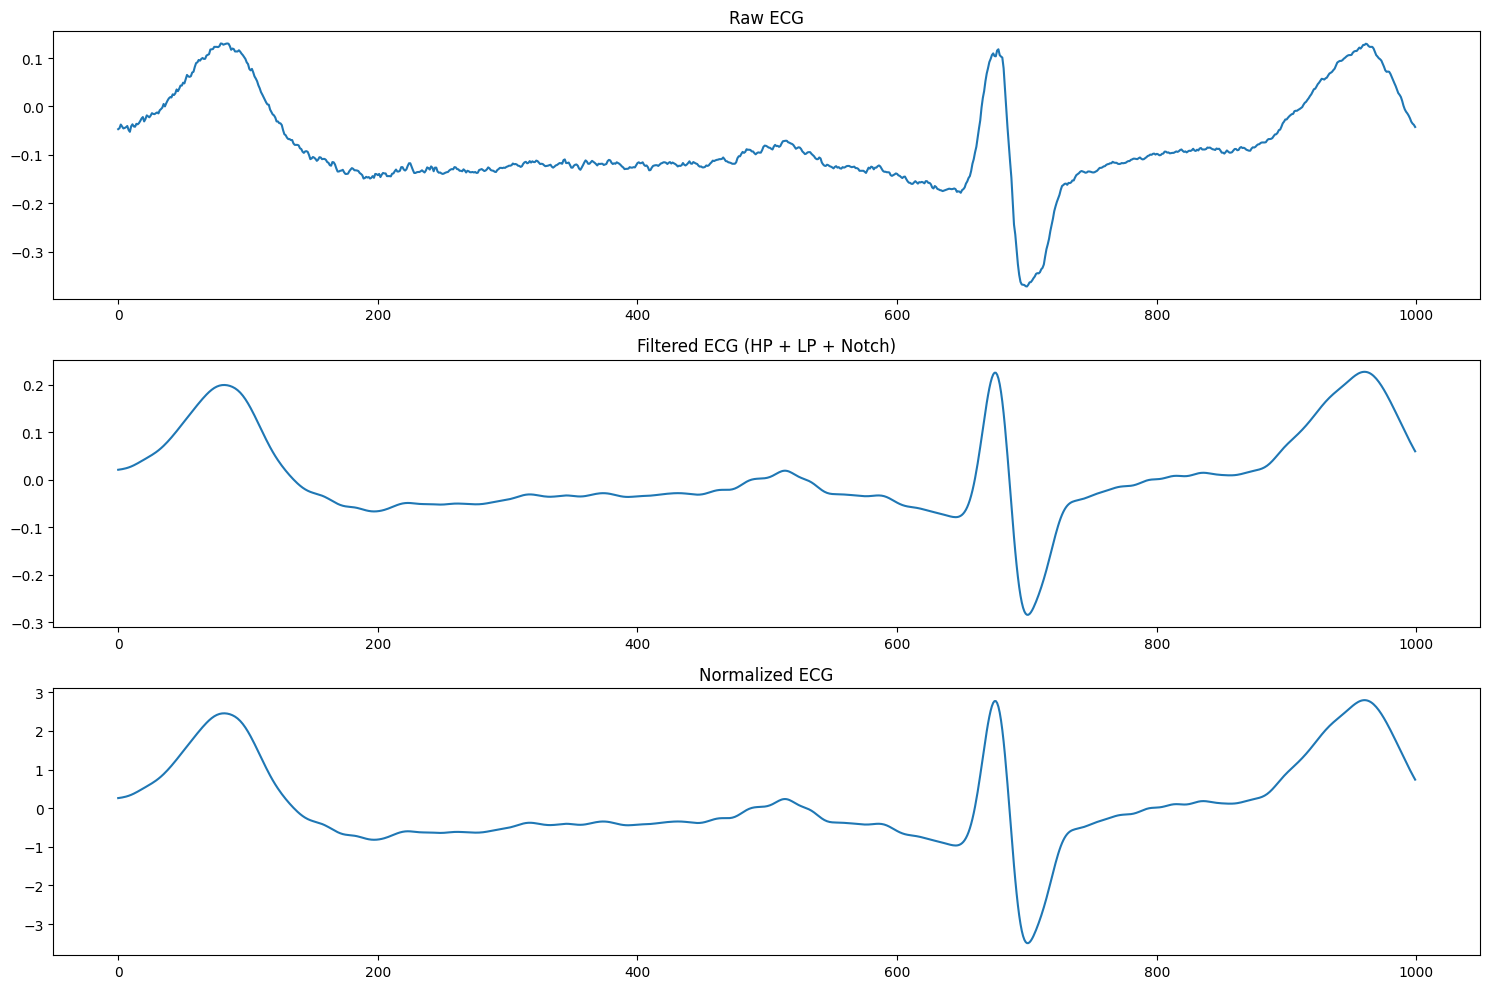

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(raw_signal[:1000])
plt.title("Raw ECG")

plt.subplot(3, 1, 2)
plt.plot(filtered_signal[:1000])
plt.title("Filtered ECG (HP + LP + Notch)")

plt.subplot(3, 1, 3)
plt.plot(normalized_signal[:1000])
plt.title("Normalized ECG")

plt.tight_layout()
plt.show()


In [ ]:
print("normalized_signal identical to original?", np.allclose(raw_signal, normalized_signal))
print("filtered_signal identical to original?", np.allclose(raw_signal, filtered_signal))
print("normalized_signal identical to filtered_signal?", np.allclose(normalized_signal, filtered_signal))


normalized_signal identical to original? False
filtered_signal identical to original? False
normalized_signal identical to filtered_signal? False


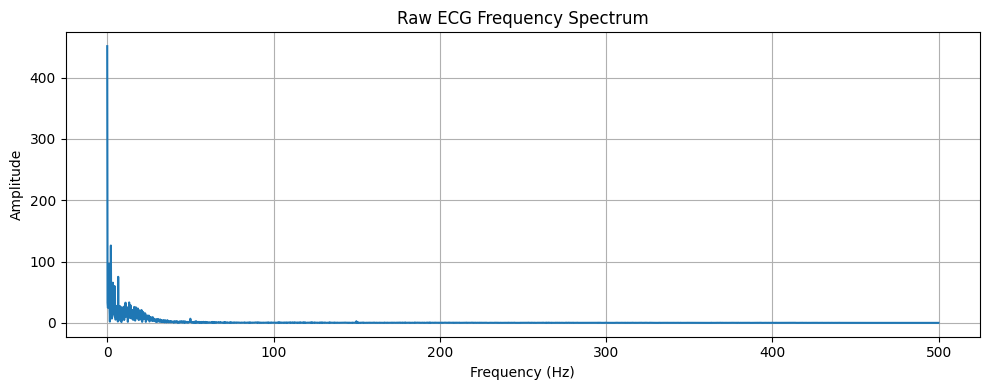

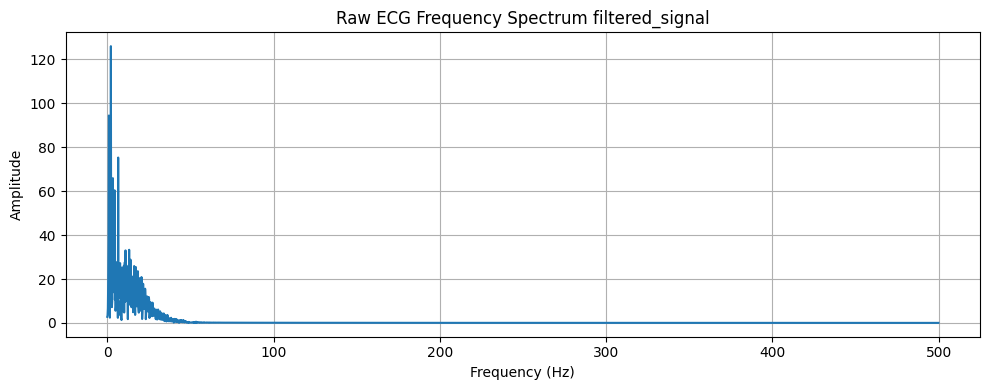

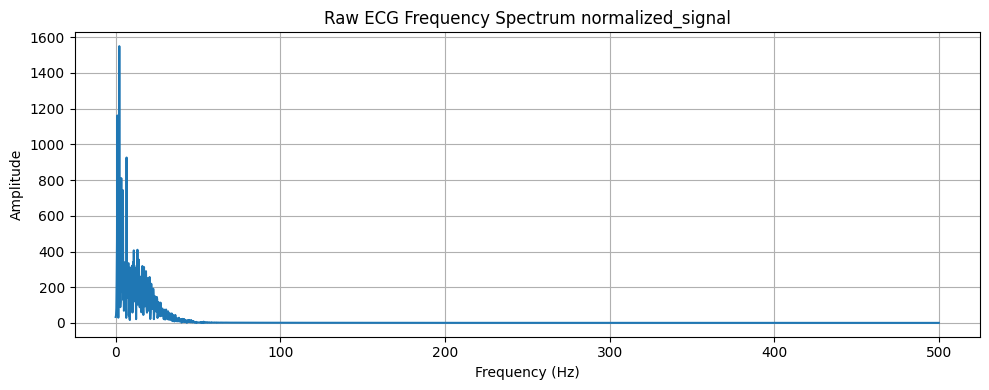

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(raw_signal[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_signal[:5000], fs, title="Raw ECG Frequency Spectrum filtered_signal")
plot_frequency_spectrum(normalized_signal[:5000], fs, title="Raw ECG Frequency Spectrum normalized_signal")


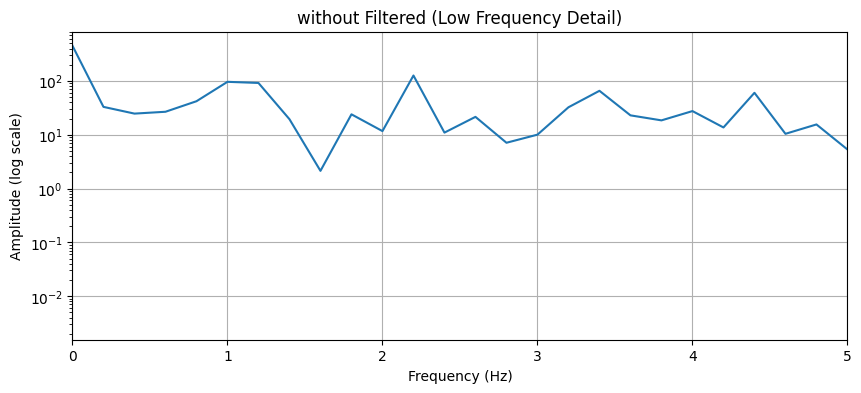

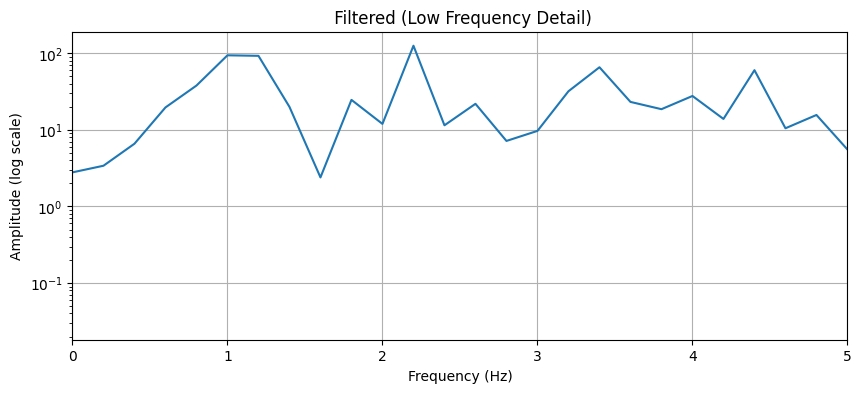

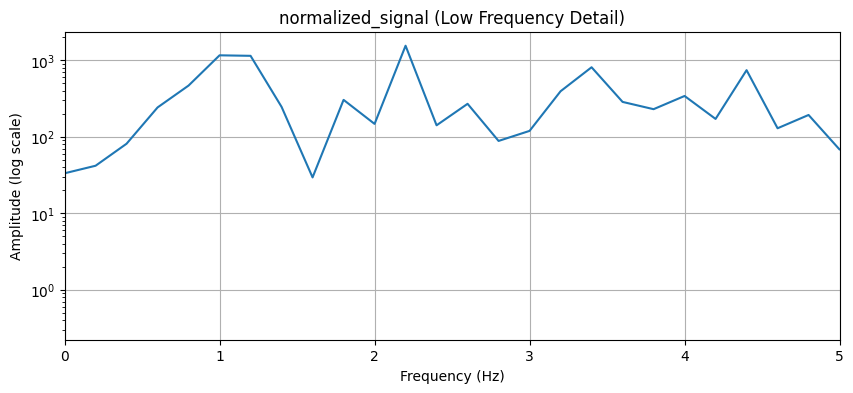

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(raw_signal[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_signal[:5000], fs, " Filtered")
plot_frequency_spectrum(normalized_signal[:5000], fs, "normalized_signal")

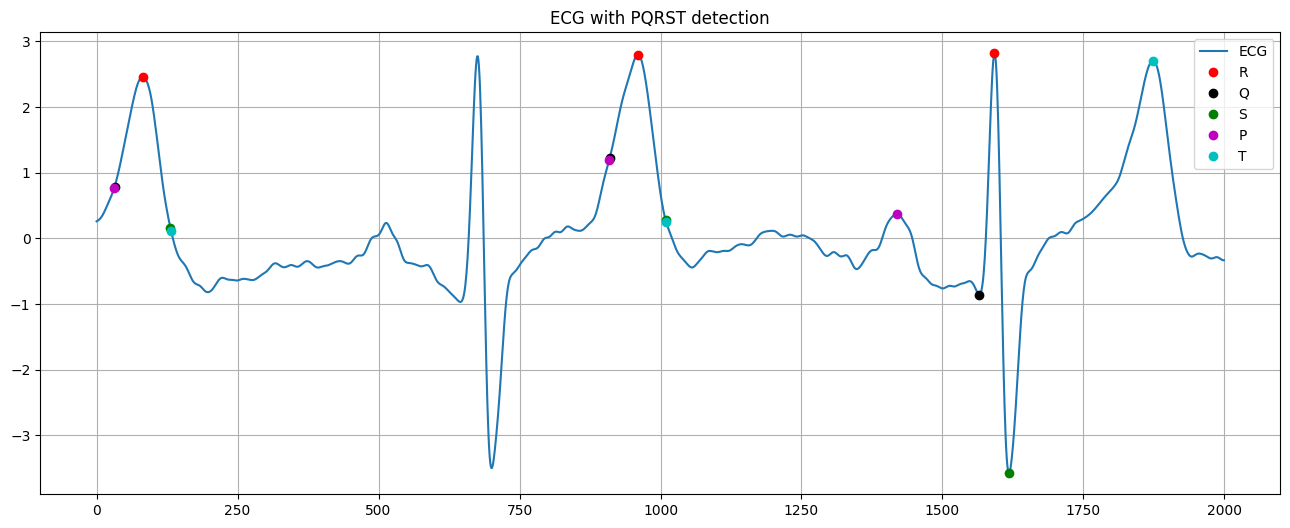

In [ ]:
r_peaks, _ = find_peaks(normalized_signal, distance=int(fs * 0.6), height=np.mean(normalized_signal))

# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(normalized_signal, r_peaks, fs)

# === Plot with all points ===
plt.figure(figsize=(16, 6))
plt.plot(normalized_signal[:2000], label="ECG")
plt.plot(r_peaks[r_peaks < 2000], normalized_signal[r_peaks[r_peaks < 2000]], 'ro', label="R")
plt.plot(q_waves[q_waves < 2000], normalized_signal[q_waves[q_waves < 2000]], 'ko', label="Q")
plt.plot(s_waves[s_waves < 2000], normalized_signal[s_waves[s_waves < 2000]], 'go', label="S")
plt.plot(p_waves[p_waves < 2000], normalized_signal[p_waves[p_waves < 2000]], 'mo', label="P")
plt.plot(t_waves[t_waves < 2000], normalized_signal[t_waves[t_waves < 2000]], 'co', label="T")
plt.title("ECG with PQRST detection")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# === Print values of detected PQRST waves ===
print("Number of beats detected:", len(r_peaks))
print("\nP-wave indices and values:")
for idx in p_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nQ-wave indices and values:")
for idx in q_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nR-wave indices and values:")
for idx in r_peaks:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nS-wave indices and values:")
for idx in s_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nT-wave indices and values:")
for idx in t_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")


Number of beats detected: 127

P-wave indices and values:
Index: 31, Value: 0.7620624529041475
Index: 909, Value: 1.1928288970712144
Index: 1419, Value: 0.37134682490221105
Index: 2341, Value: 0.39701944928799987
Index: 3618, Value: 1.6068882633095125
Index: 4147, Value: 0.2669300725794903
Index: 5090, Value: 0.33842586280142917
Index: 6016, Value: -0.05877349509562022
Index: 6961, Value: 0.2814254542056805
Index: 7912, Value: 0.4569486669195481
Index: 8842, Value: 0.5303664537006894
Index: 10139, Value: 1.2104432128576637
Index: 10657, Value: 0.4353204591994269
Index: 11591, Value: 0.5314060130059683
Index: 12888, Value: 1.1707669851738842
Index: 13416, Value: 0.48489822392328297
Index: 14337, Value: 0.44120088803800156
Index: 15231, Value: 0.24855541225803635
Index: 16130, Value: 0.04002783688761125
Index: 17057, Value: 0.13223493361224048
Index: 17970, Value: 0.19025026490463423
Index: 18880, Value: 0.3117916057000741
Index: 19798, Value: 0.029219449814278046
Index: 20738, Value: 0.

In [ ]:
####################### Ischemique #############

In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch

i=0
path=f"{WORK_DIR}/ECG_Data/Ischemic"
if i> len(ListFilesIschemiques) :
  z=len(ListFilesIschemiques)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesIschemiques[z][:-4]}')

# Step 1: Read ECG
raw_signal = record.p_signal[:, 0]
fs = record.fs

# Step 2: Apply filters
filtered_signal = preprocess_ecg(raw_signal, fs)

# Step 3: Normalize
normalized_signal = (filtered_signal - np.mean(filtered_signal)) / np.std(filtered_signal)

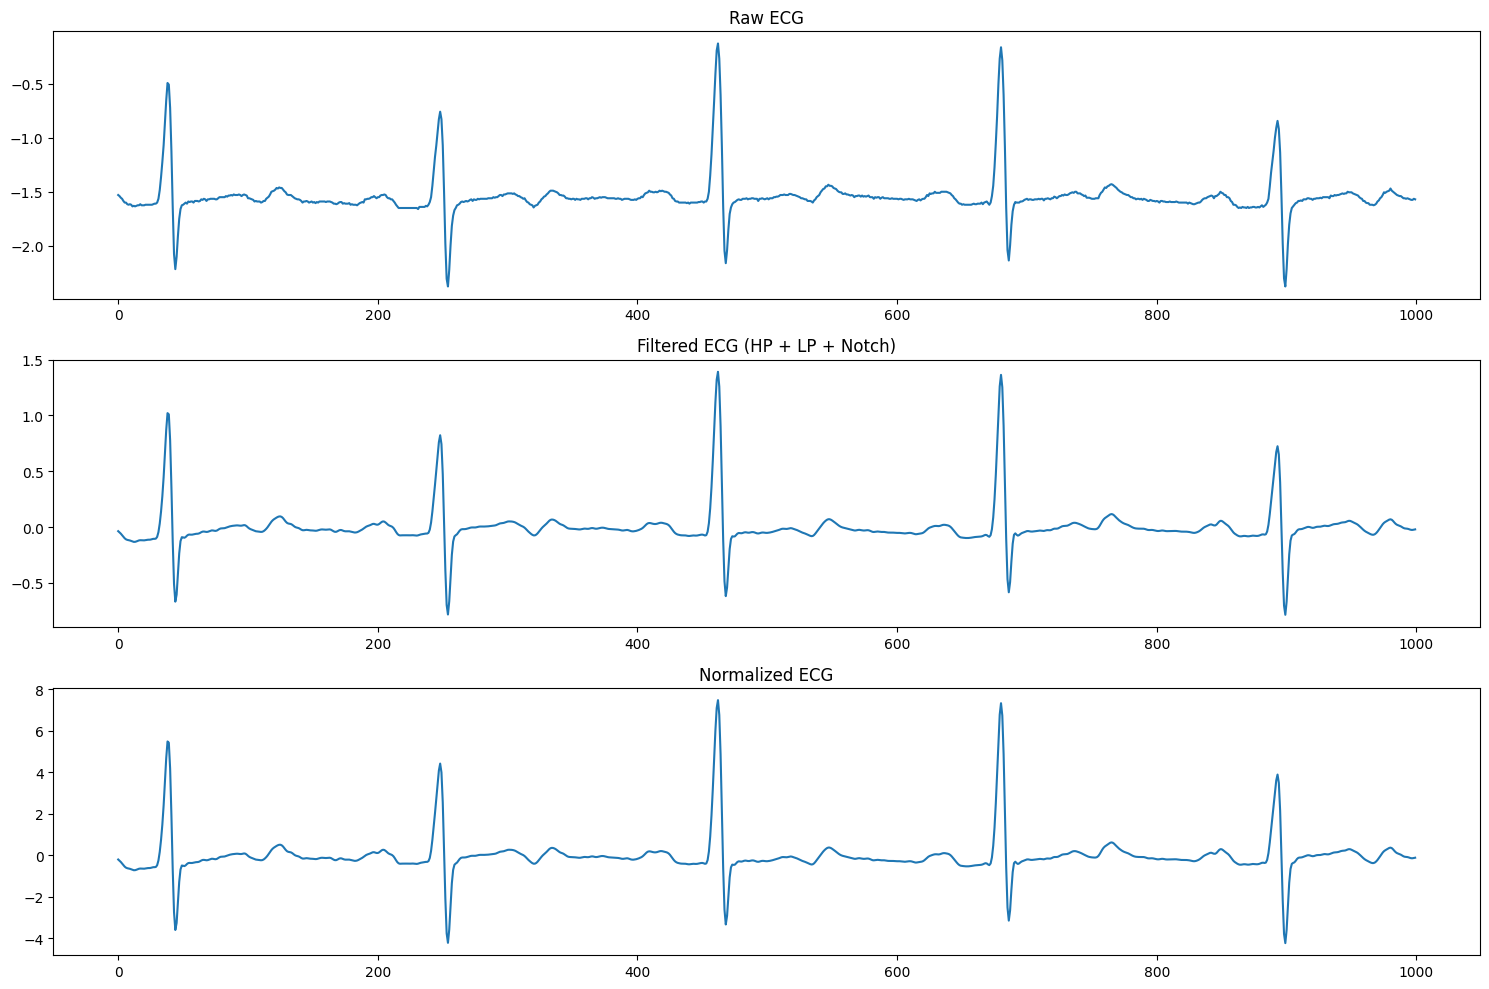

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(raw_signal[:1000])
plt.title("Raw ECG")

plt.subplot(3, 1, 2)
plt.plot(filtered_signal[:1000])
plt.title("Filtered ECG (HP + LP + Notch)")

plt.subplot(3, 1, 3)
plt.plot(normalized_signal[:1000])
plt.title("Normalized ECG")

plt.tight_layout()
plt.show()

In [ ]:
print("normalized_signal identical to original?", np.allclose(raw_signal, normalized_signal))
print("filtered_signal identical to original?", np.allclose(raw_signal, filtered_signal))
print("normalized_signal identical to filtered_signal?", np.allclose(normalized_signal, filtered_signal))

normalized_signal identical to original? False
filtered_signal identical to original? False
normalized_signal identical to filtered_signal? False


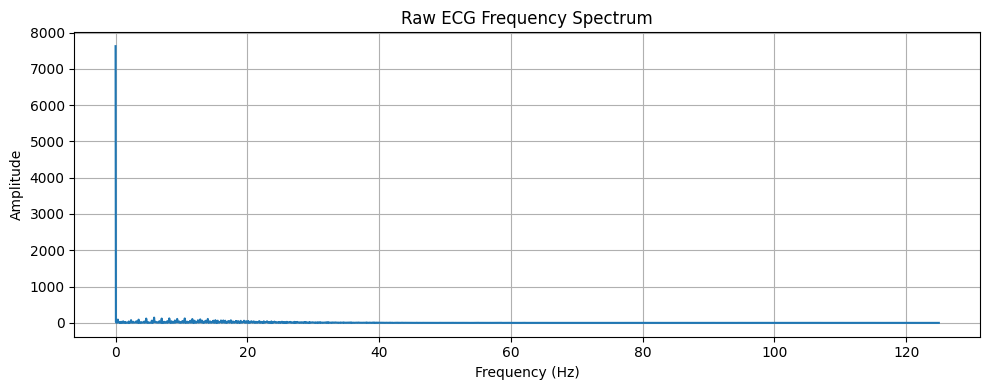

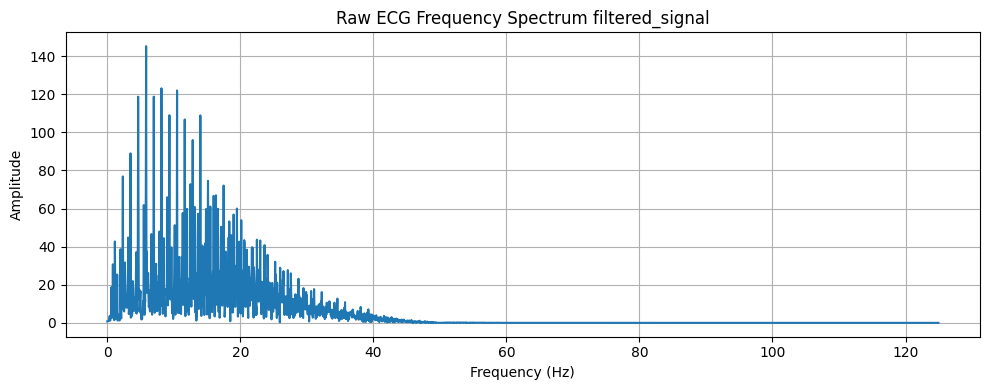

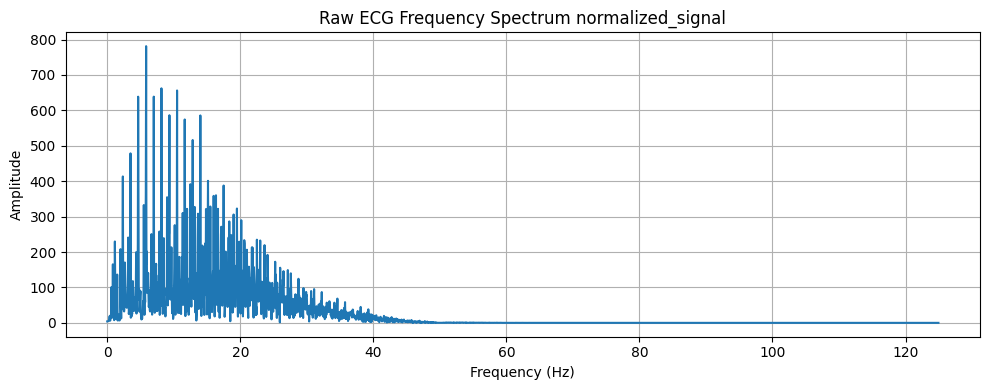

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(raw_signal[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_signal[:5000], fs, title="Raw ECG Frequency Spectrum filtered_signal")
plot_frequency_spectrum(normalized_signal[:5000], fs, title="Raw ECG Frequency Spectrum normalized_signal")


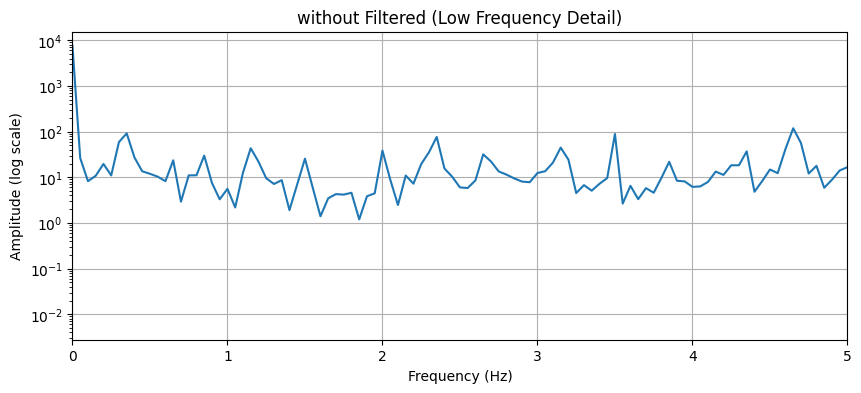

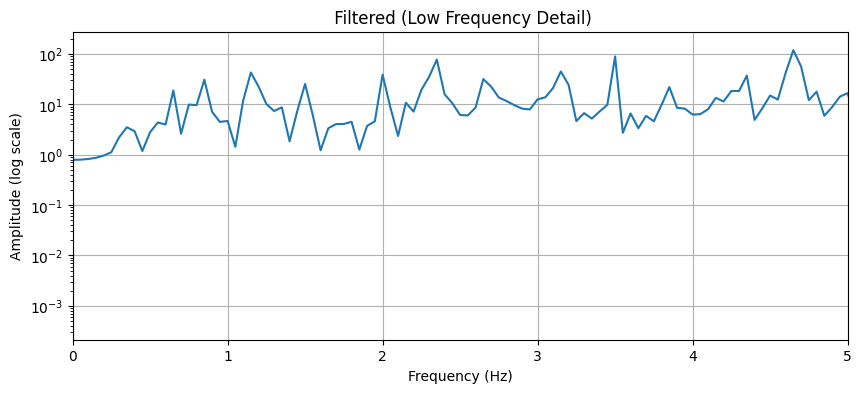

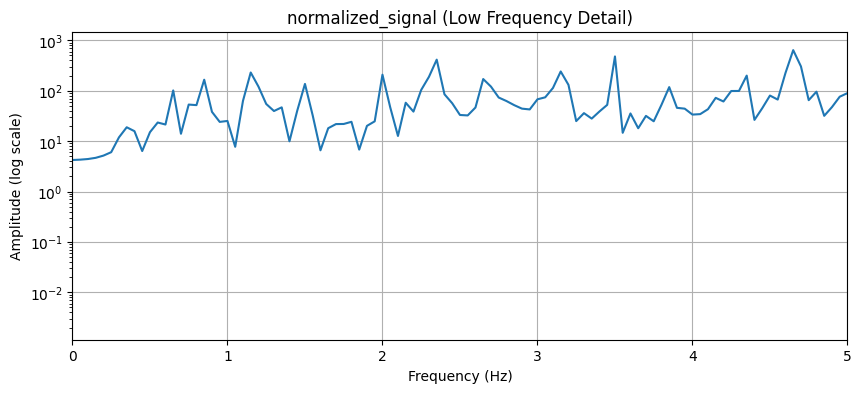

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(raw_signal[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_signal[:5000], fs, " Filtered")
plot_frequency_spectrum(normalized_signal[:5000], fs, "normalized_signal")

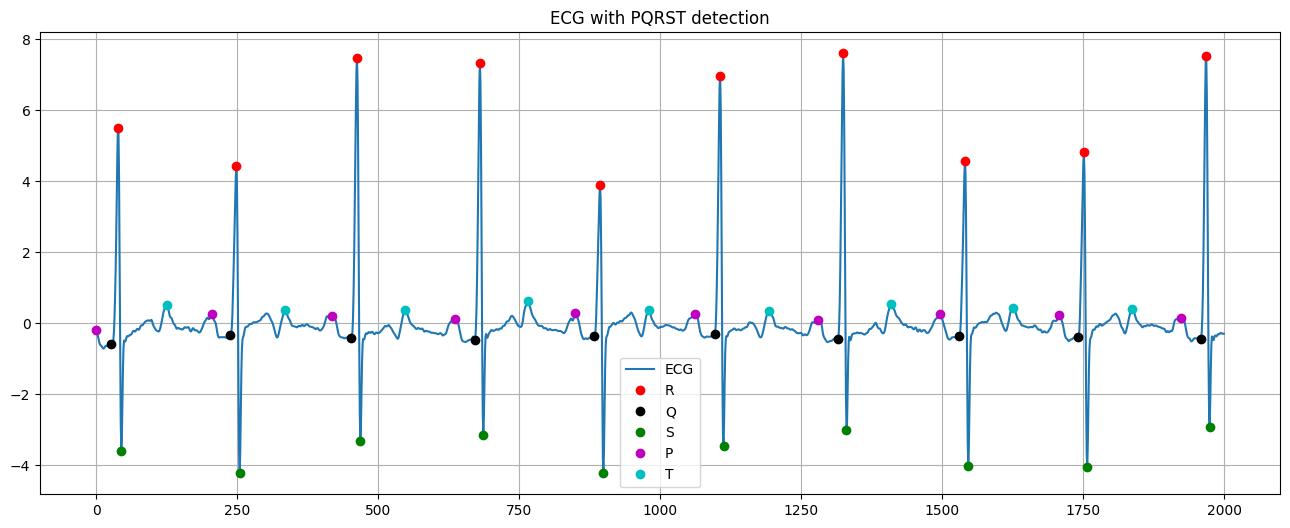

In [ ]:
r_peaks, _ = find_peaks(normalized_signal, distance=int(fs * 0.6), height=np.mean(normalized_signal))

# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(normalized_signal, r_peaks, fs)

# === Plot with all points ===
plt.figure(figsize=(16, 6))
plt.plot(normalized_signal[:2000], label="ECG")
plt.plot(r_peaks[r_peaks < 2000], normalized_signal[r_peaks[r_peaks < 2000]], 'ro', label="R")
plt.plot(q_waves[q_waves < 2000], normalized_signal[q_waves[q_waves < 2000]], 'ko', label="Q")
plt.plot(s_waves[s_waves < 2000], normalized_signal[s_waves[s_waves < 2000]], 'go', label="S")
plt.plot(p_waves[p_waves < 2000], normalized_signal[p_waves[p_waves < 2000]], 'mo', label="P")
plt.plot(t_waves[t_waves < 2000], normalized_signal[t_waves[t_waves < 2000]], 'co', label="T")
plt.title("ECG with PQRST detection")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# === Print values of detected PQRST waves ===
print("Number of beats detected:", len(r_peaks))
print("\nP-wave indices and values:")
for idx in p_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nQ-wave indices and values:")
for idx in q_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nR-wave indices and values:")
for idx in r_peaks:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nS-wave indices and values:")
for idx in s_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")

print("\nT-wave indices and values:")
for idx in t_waves:
    print(f"Index: {idx}, Value: {normalized_signal[idx]}")


Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
Index: 835390, Value: 0.36914706024044097
Index: 835598, Value: 0.5081751798782917
Index: 835803, Value: 0.30444477725615554
Index: 836009, Value: 0.3582886016055532
Index: 836218, Value: 0.46020550687157546
Index: 836424, Value: 0.3916741111248148
Index: 836623, Value: 0.28052683802121997
Index: 836833, Value: 0.38462238767427315
Index: 837040, Value: 0.4536833047992129
Index: 837238, Value: 0.36233111410513597
Index: 837439, Value: 0.3165071146615168
Index: 837643, Value: 0.4137633126613868
Index: 837845, Value: 0.4901607083314961
Index: 838042, Value: 0.30381194087005275
Index: 838243, Value: 0.35744924126312055
Index: 838450, Value: 0.5142780713771711
Index: 838651, Value: 0.44877118146075845
Index: 838850, Value: 0.2959685759171196
Index: 839051, Value: 0.3471127501887074
Index: 839257, Value: 0.4519234265252629
Index: 839462, Value: 0.5331934150358928
Index: 839660, Value: 0.3100988969638662
Index: 8398

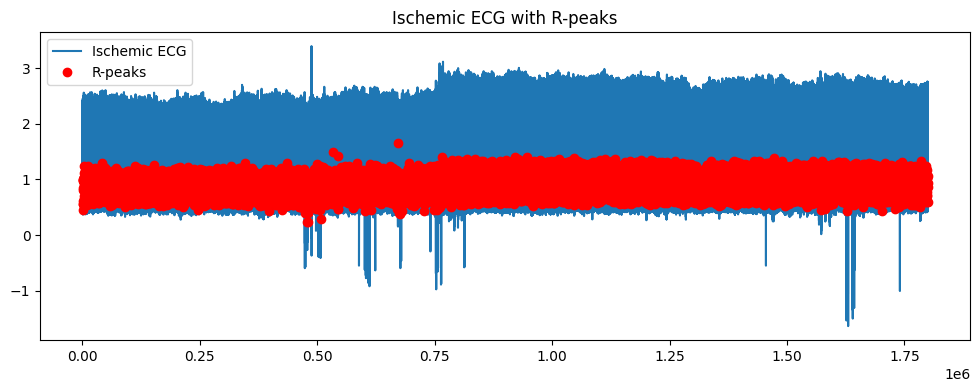

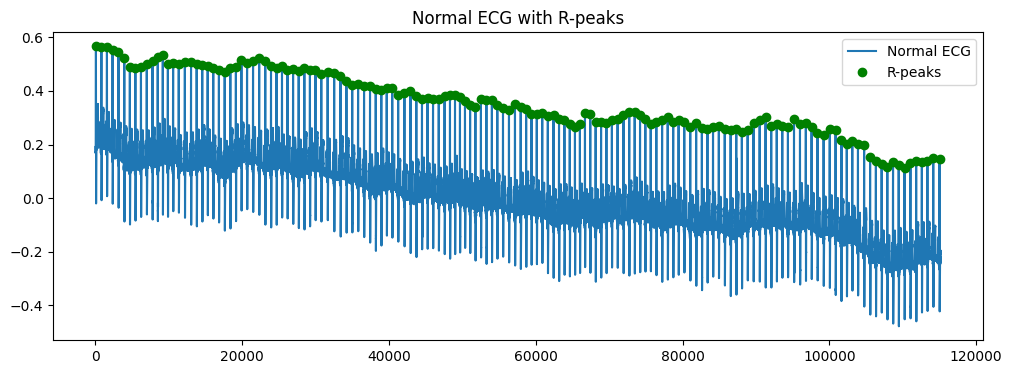

In [ ]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

def load_ecg(record_path, is_ischemic=True):
    record = wfdb.rdrecord(record_path)
    signal = record.p_signal[:, 0]  # Take channel 0
    fs = record.fs

    if is_ischemic:
        # Load annotations for ischemic signal
        ann = wfdb.rdann(record_path, 'atr')
        r_peaks = ann.sample
    else:
        # No annotations: detect R-peaks automatically
        r_peaks, _ = find_peaks(signal, distance=fs*0.6, height=np.mean(signal))

    return signal, fs, r_peaks

# === Example 1: Ischemic ECG ===
ischemic_path = f"{WORK_DIR}/ECG_Data/Ischemic/e0103"  # Without extension
signal1, fs1, r_peaks1 = load_ecg(ischemic_path, is_ischemic=True)

# === Example 2: Normal ECG ===
normal_path = f"{WORK_DIR}/ECG_Data/Normal/s0301lre"  # Without extension
signal2, fs2, r_peaks2 = load_ecg(normal_path, is_ischemic=False)

# === Plot for ischemic signal ===
plt.figure(figsize=(12, 4))
plt.plot(signal1, label='Ischemic ECG')
plt.plot(r_peaks1, signal1[r_peaks1], 'ro', label='R-peaks')
plt.title('Ischemic ECG with R-peaks')
plt.legend()
plt.show()

# === Plot for normal signal ===
plt.figure(figsize=(12, 4))
plt.plot(signal2, label='Normal ECG')
plt.plot(r_peaks2, signal2[r_peaks2], 'go', label='R-peaks')
plt.title('Normal ECG with R-peaks')
plt.legend()
plt.show()


In [ ]:
##########################3 Extraction des caracteristique

In [ ]:
beat_duration = int(0.6 * fs)  # 600 ms
all_beats = []
all_labels = []

def extract_beats(normalized_signal, r_peaks, label, fs):
    beats = []
    for r in r_peaks:
        start = max(r - beat_duration // 2, 0)
        end = min(r + beat_duration // 2, len(normalized_signal))
        beat = normalized_signal[start:end]

        # Padding si le segment est trop court
        if len(beat) < beat_duration:
            beat = np.pad(beat, (0, beat_duration - len(beat)), 'constant')
        beats.append(beat)
    return beats, [label] * len(beats)


In [ ]:
import os

path_ischemic = f"{WORK_DIR}/ECG_Data/Ischemic"
path_normal = f"{WORK_DIR}/ECG_Data/Normal"

ischemic_files = [f for f in os.listdir(path_ischemic) if f.endswith('.dat')]
normal_files = [f for f in os.listdir(path_normal) if f.endswith('.dat')]

for file in ischemic_files:
    record = wfdb.rdrecord(os.path.join(path_ischemic, file[:-4]))
    signal = record.p_signal[:, 0]
    fs = record.fs
    filtered = preprocess_ecg(signal, fs)
    normed = (filtered - np.mean(filtered)) / np.std(filtered)
    r_peaks, _ = find_peaks(normed, distance=int(fs * 0.6), height=np.mean(normed))
    beats, labels = extract_beats(normed, r_peaks, 1, fs)  # 1 = Ischemic
    all_beats.extend(beats)
    all_labels.extend(labels)

for file in normal_files:
    record = wfdb.rdrecord(os.path.join(path_normal, file[:-4]))
    signal = record.p_signal[:, 0]
    fs = record.fs
    filtered = preprocess_ecg(signal, fs)
    normed = (filtered - np.mean(filtered)) / np.std(filtered)
    r_peaks, _ = find_peaks(normed, distance=int(fs * 0.6), height=np.mean(normed))
    beats, labels = extract_beats(normed, r_peaks, 0, fs)  # 0 = Normal
    all_beats.extend(beats)
    all_labels.extend(labels)

all_beats = np.array(all_beats)
all_labels = np.array(all_labels)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50)
beats_pca = pca.fit_transform(all_beats)
from sklearn.utils import resample

# Convertir en dataframe pour faciliter
import pandas as pd
df = pd.DataFrame(beats_pca)
df['label'] = all_labels

# Séparer
df_majority = df[df.label == 1]
df_minority = df[df.label == 0]

# Équilibrer
df_majority_downsampled = resample(df_majority,
                                   replace=False,
                                   n_samples=len(df_minority),
                                   random_state=42)

df_balanced = pd.concat([df_majority_downsampled, df_minority])
df_balanced = df_balanced.sample(frac=1)  # shuffle

X = df_balanced.drop('label', axis=1).values
y = df_balanced['label'].values


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

model = Sequential([
    Flatten(input_shape=(beats_pca.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')  # Binaire : 0 = normal, 1 = ischemic
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X , y, epochs=3, batch_size=32, validation_split=0.2)


Epoch 1/3


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


528/528 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9419 - loss: 0.1747 - val_accuracy: 0.9957 - val_loss: 0.0165
Epoch 2/3
528/528 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9979 - loss: 0.0089 - val_accuracy: 0.9979 - val_loss: 0.0096
Epoch 3/3
528/528 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9992 - loss: 0.0038 - val_accuracy: 0.9986 - val_loss: 0.0093


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(beats_pca)
y_pred = (y_pred > 0.5).astype(int)

print(confusion_matrix(all_labels, y_pred))
print(classification_report(all_labels, y_pred))


8368/8368 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step
[[ 10548      7]
 [   456 256756]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     10555
           1       1.00      1.00      1.00    257212

    accuracy                           1.00    267767
   macro avg       0.98      1.00      0.99    267767
weighted avg       1.00      1.00      1.00    267767



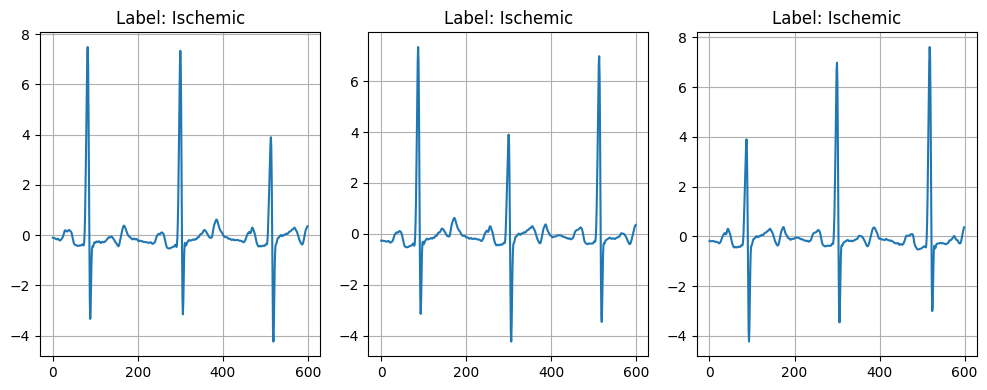

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.plot(all_beats[i+3])
    plt.title(f"Label: {'Ischemic' if all_labels[i+3] else 'Normal'}")
    plt.grid()
plt.tight_layout()
plt.show()
